# HL Tau Band 6 w/ NUFFT
This notebbook loads the raw table, initializes the network (warm start), and fits one image to all four frequency channels in Band 6.

`quick` fits a small sample. `full` uses the 512-pixel settings. (I show the results of `full` at the end anyway, which was run on a GPU on teh resnick cluster)

Cheyanne Shariat

In [10]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('XLA_PYTHON_CLIENT_PREALLOCATE', 'false')

from pathlib import Path
from itertools import islice
from collections import OrderedDict
import json, time, uuid
from importlib.util import find_spec
if find_spec('kine') is None or find_spec('kine.fourier') is None:
    raise RuntimeError(
        "This kernel has an older Kine without the NUFFT module. "
        "Select the team's NUFFT Kine environment, restart, and run from the top.")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import AsinhNorm
import jax
import jax.numpy as jnp
import optax
import ehtim as eh
from flax import linen as nn
from kine.fourier import NUFFT
from kine.model import NeuralField
from kine.trainer import Trainer
from kine.utils import get_grid

# Run beside this notebook, or from its parent folder.
BASE = Path.cwd()
if not (BASE / 'data/hl_tau_b6_example.txt').exists():
    BASE = BASE / 'HL_Tau_NUFFT'

MODE = 'quick'  # Change to 'full' for the presented settings.
RAW_FILE = BASE / 'data/hl_tau_b6_example.txt'
if MODE == 'full':
    RAW_FILE = Path('HLTau.B6.SelfCal.PhaseShift.ms.uvtable')  # Set data path.


# These are the defaults i Used for the full run
settings = dict(npix=512, fov_arcsec=4., width=256, depth=4, pe=10,
         init_steps=2000, fit_steps=3000, init_lr=.01, fit_lr=.003,
         decay_step=2000, decay_factor=.3, init_fwhm_arcsec=.8,
         seed=163, nufft_eps=1e-6)


if MODE == 'quick':
    settings.update(npix=32, width=32, depth=1, pe=4,
             init_steps=300, fit_steps=150, decay_step=100)
elif MODE == 'full':
    assert jax.default_backend() == 'gpu', 'Use a GPU kernel for the full run.'
else:
    raise ValueError("MODE must be 'quick' or 'full'.")
assert RAW_FILE.is_file(), f'Set RAW_FILE to your Band 6 table: {RAW_FILE}'
if MODE == 'quick':
    assert RAW_FILE.stat().st_size < 2_000_000, 'Use the bundled sample in quick mode.'
print('Mode:', MODE, '| Device:', jax.devices()[0])
print(f"{settings['npix']} pixels per side; {settings['depth']+1} hidden layers of width {settings['width']}; PE {settings['pe']}")


Mode: quick | Device: TFRT_CPU_0
32 pixels per side; 2 hidden layers of width 32; PE 4


## 1. Load Stokes I
Keep $u,v$ in wavelength units. Calculate stokes I visibilty, $V_I=(V_{XX}+V_{YY})/2$ and
$\sigma_I=\tfrac12\sqrt{1/w_{XX}+1/w_{YY}}$.
This assumes independent XX/YY noise and uses inverse variance weights.

I excluded rows where XX/YY rows are both 0.

btw Band 6 is ~220-240 GHz

In [11]:
# read band 6 data, randomly chosen for this test
# reuses some code from KG and CS's NUFFT push to github
def read_band6(path):
    parts = {key: [] for key in ['uv', 'vis', 'sigma', 'frequency_GHz']}
    raw_rows = zero_rows = 0
    preview = None
    with path.open() as stream:
        next(stream)
        while lines := list(islice(stream, 50_000)):
            table = np.loadtxt(lines, ndmin=2)
            if table.shape[1] != 13 or not np.isfinite(table).all():
                raise ValueError('Expected 13 finite columns. Check the input table.')
            if np.any(table[:, 11:13] <= 0) or np.any(table[:, 3] == table[:, 4]):
                raise ValueError('Check nonpositive weights or autocorrelations.')
            XX = table[:, 7] + 1j*table[:, 8]
            YY = table[:, 9] + 1j*table[:, 10]
            if preview is None:
                preview = pd.DataFrame({'Frequency (GHz)': table[:5, 2],
                                        'XX': XX[:5], 'YY': YY[:5],
                                        'Weight XX': table[:5, 11], 'Weight YY': table[:5, 12]})
            keep = (XX != 0) | (YY != 0)
            raw_rows += len(table)
            zero_rows += int((~keep).sum())
            parts['uv'].append(table[keep, 5:7])
            parts['vis'].append(((XX[keep]+YY[keep])/2).astype(np.complex64))
            parts['sigma'].append(.5*np.sqrt(1/table[keep, 11] + 1/table[keep, 12]))
            parts['frequency_GHz'].append(table[keep, 2])
    return {key: np.concatenate(value) for key, value in parts.items()}, preview, raw_rows, zero_rows

rows, preview, raw_count, zero_count = read_band6(RAW_FILE)
uv, target, sigma = rows['uv'], rows['vis'], rows['sigma']
frequencies = np.unique(rows['frequency_GHz'])
print('Frequencies (GHz):', frequencies)
print(f'{len(target):,} fitted measurements; {zero_count:,} both-zero rows excluded')
display(preview)
display(pd.DataFrame({'u (wavelengths)': uv[:5, 0], 'v (wavelengths)': uv[:5, 1],
                      'Stokes I (assumed Jy)': target[:5], 'sigma (assumed Jy)': sigma[:5]}))

# look at the data

Frequencies (GHz): [224.75 226.75 239.25 241.25]
512 fitted measurements; 0 both-zero rows excluded


,Frequency (GHz),XX,YY,Weight XX,Weight YY
0,239.25,0.453591+0.029127j,0.507274-0.059779j,376897.2,328836.7
1,239.25,0.140096-0.035502j,0.104230-0.006435j,432836.6,426845.3
2,241.25,-0.019952+0.125383j,0.047834-0.054871j,332375.5,362803.3
3,241.25,0.182007-0.048849j,0.166402+0.030430j,359760.0,382817.5
4,224.75,0.008864-0.059248j,-0.085582+0.060125j,391865.9,496033.0


,u (wavelengths),v (wavelengths),Stokes I (assumed Jy),sigma (assumed Jy)
0,18602.05,-114192.80,0.480432-0.015326j,0.001193
1,141109.50,-128204.20,0.122163-0.020968j,0.001079
2,-427729.70,522281.10,0.013941+0.035256j,0.001201
3,348565.40,-70518.33,0.174204-0.009210j,0.001161
4,-629154.20,183193.60,-0.038359+0.000439j,0.001069


## 2. Choose the grid and starting image
Use a 0.8-arcsec Gaussian for the warm star. Its starting flux comes from the shortest 0.5% of baselines, with >= 32 measurements.

In [4]:
n, fov = settings['npix'], settings['fov_arcsec']
pixel_radians = fov*eh.RADPERAS/n

prior = eh.image.Image(np.zeros((n, n)), pixel_radians, 0, 0,
                       rf=float(rows['frequency_GHz'].mean())*1e9, source='HL Tau')
grid = get_grid(n, n)

rho = np.hypot(uv[:, 0], uv[:, 1])
short = np.argsort(rho)[:max(32, int(.005*len(rho)))]
flux = float(np.average(target[short].real, weights=1/sigma[short]**2))

axis = ((n-1)/2 - np.arange(n))*fov/n
x, y = np.meshgrid(axis, axis)
initial = np.exp(-4*np.log(2)*(x*x+y*y)/settings['init_fwhm_arcsec']**2)
initial *= flux/initial.sum()
print(f'Initial flux scale: {flux:.4f} assumed Jy')


Initial flux scale: 0.7321 assumed Jy


## 3. Prepare NUFFT
Check 16 measurements against ehtim's direct matrix, including image gradients. The full fit uses NUFFT still

In [ ]:
from ehtim.observing.obs_helpers import ftmatrix

check_indices = np.random.default_rng(settings['seed']).choice(len(target), 16, replace=False)
check_uv = uv[check_indices]
small_nufft = NUFFT.from_uv(check_uv, prior, eps=settings['nufft_eps'])
direct = jnp.asarray(ftmatrix(pixel_radians, n, n, check_uv, pulse=prior.pulse), dtype=jnp.complex64)
proposed = jnp.asarray(initial, dtype=jnp.float32)
direct_vis = direct @ proposed.ravel()
nufft_vis = small_nufft(proposed)[0]
visibility_difference = float(jnp.linalg.norm(direct_vis-nufft_vis)/jnp.linalg.norm(direct_vis))

def direct_loss(image):
    return jnp.mean(jnp.abs(direct @ image.ravel() - target[check_indices])**2)

def nufft_loss(image):
    return jnp.mean(jnp.abs(small_nufft(image)[0] - target[check_indices])**2)

direct_gradient = jax.grad(direct_loss)(proposed)
nufft_gradient = jax.grad(nufft_loss)(proposed)
gradient_difference = float(jnp.linalg.norm(direct_gradient-nufft_gradient)/jnp.linalg.norm(direct_gradient))
assert visibility_difference < 1e-4 and gradient_difference < 5e-4
print(f'Relative visibility difference: {visibility_difference:.2g}')
print(f'Relative image-gradient difference: {gradient_difference:.2g}')
operator = NUFFT.from_uv(uv, prior, eps=settings['nufft_eps'])
jax.block_until_ready(operator.factor)
data = {'visI': {'target': jnp.asarray(target)[None, :],
                 'sigma': jnp.asarray(sigma, dtype=jnp.float32)[None, :], 'A': operator}}


Relative visibility difference: 6.7e-07
Relative image-gradient difference: 3.2e-06


## 4. Initialize the network
The full settings use 5 hidden layers of width 256 and positional encoding 10. Kine's `depth=4` gives five layers. Softplus is used to keep positive flux.

In [6]:
model = NeuralField(posenc_deg=(settings['pe'], settings['pe']), depth=settings['depth'], width=settings['width'],
                    activ=nn.gelu, outactiv=nn.softplus, outshift=0,
                    do_bnorm=True, skipat=0, scaling_i=flux/n**2)
variables = model.init(jax.random.PRNGKey(settings['seed']), grid, train=True)
schedule = optax.piecewise_constant_schedule(settings['init_lr'], {
    settings['init_steps']: settings['fit_lr']/settings['init_lr'],
    settings['init_steps']+settings['decay_step']: settings['decay_factor']})
state = Trainer.create(apply_fn=model.apply, params=variables['params'],
                       batch_stats=variables['batch_stats'], tx=optax.adamax(schedule, eps=1e-16))

def image_of(state):
    output = state.apply_fn({'params': state.params, 'batch_stats': state.batch_stats},
                            grid, train=True, mutable=['batch_stats'])[0]
    return np.asarray(output)[..., 0].reshape(n, n)

start = time.perf_counter()
init_history = []
for _ in range(settings['init_steps']):
    loss, _, _, state = Trainer.train_step(OrderedDict(
        state=state, grid=grid, init_arr=jnp.asarray(initial[..., None], dtype=jnp.float32)))
    init_history.append(float(loss))
init_seconds = time.perf_counter()-start
initialized = image_of(state)
init_error = np.linalg.norm(initialized-initial)/np.linalg.norm(initial)
assert np.isfinite(init_history).all() and init_error < .1, 'Increase initialization steps before fitting.'
print(f'Gaussian image error: {100*init_error:.2f}% after {init_seconds:.1f} s')


Gaussian image error: 2.20% after 0.5 s


## 5. Fit the measurements
Each update predicts visibilities, compares them with Stokes I, and adjusts the network.

In [7]:
start = time.perf_counter()
fit_history = []
image_changes = []
previous_image = initialized
for step in range(settings['fit_steps']):
    loss, _, _, state = Trainer.train_step(OrderedDict(state=state, grid=grid, data=data))
    fit_history.append(float(loss))
    if (step+1) % 100 == 0 or step+1 == settings['fit_steps']:
        current_image = image_of(state)
        image_changes.append({'step': step+1, 'relative_image_change': float(
            np.linalg.norm(current_image-previous_image)/np.linalg.norm(previous_image))})
        previous_image = current_image
        print(f"Update {step+1}: loss {fit_history[-1]:.3f}")
fit_seconds = time.perf_counter()-start
image = image_of(state)
assert np.isfinite(fit_history).all() and np.isfinite(image).all()
print(f'Fitting time: {fit_seconds:.1f} s')


Update 100: loss 5083.675
Update 150: loss 5069.751
Fitting time: 0.3 s


## 6. Inspect and save

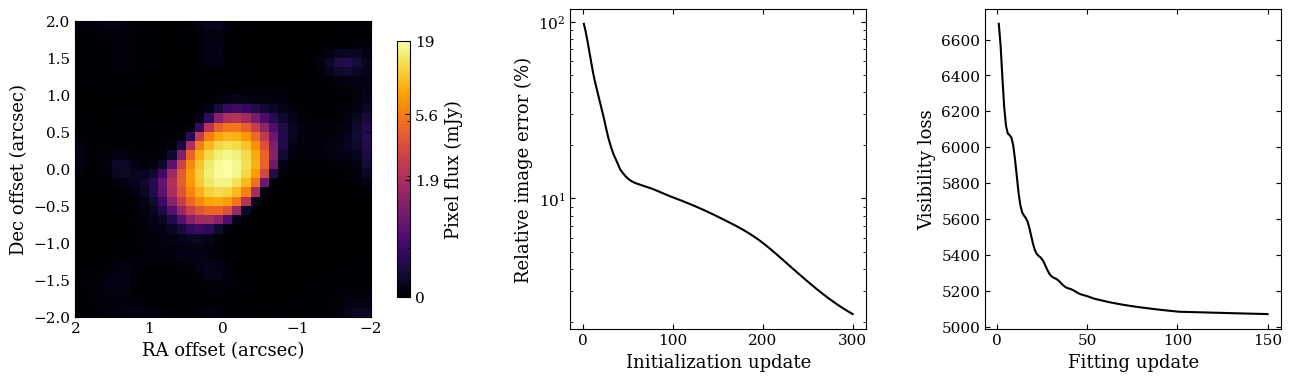

Saved: outputs/quick-20261116-144602-46bb8b


In [8]:
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['DejaVu Serif'],
                     'mathtext.fontset': 'cm', 'axes.labelsize': 13, 'xtick.labelsize': 11,
                     'ytick.labelsize': 11, 'xtick.direction': 'in', 'ytick.direction': 'in',
                     'xtick.top': True, 'ytick.right': True, 'pdf.fonttype': 42})

def show_fit(image, initial, init_history, fit_history, fov):
    fig, axes = plt.subplots(1, 3, figsize=(12.8, 3.7), layout='constrained')
    fig.get_layout_engine().set(wspace=.12)
    values = image*1000
    im = axes[0].imshow(values, origin='upper', extent=[fov/2, -fov/2, -fov/2, fov/2],
                         cmap='inferno', interpolation='nearest',
                         norm=AsinhNorm(linear_width=.03*values.max(), vmin=0, vmax=values.max()))
    axes[0].set(xlabel='RA offset (arcsec)', ylabel='Dec offset (arcsec)')
    fig.colorbar(im, ax=axes[0], label='Pixel flux (mJy)', shrink=.8,
                 ticks=values.max()*np.array([0, .1, .3, 1]), format='%.2g')
    error = 100*np.sqrt(np.asarray(init_history)/np.mean(initial**2))
    axes[1].semilogy(np.arange(1, len(error)+1), error, color='black')
    axes[1].set(xlabel='Initialization update', ylabel='Relative image error (%)')
    axes[2].plot(np.arange(1, len(fit_history)+1), fit_history, color='black')
    axes[2].set(xlabel='Fitting update', ylabel='Visibility loss')
    return fig

fig = show_fit(image, initial, init_history, fit_history, settings['fov_arcsec'])
plt.show()

# Each run gets a new directory. Existing results stay unchanged.
output = BASE / 'outputs' / f"{MODE}-{time.strftime('%Y%m%d-%H%M%S')}-{uuid.uuid4().hex[:6]}"
output.mkdir(parents=True)
np.savez_compressed(output / 'result.npz', image=image, initial=initial, initialized=initialized,
                    init_history=init_history, history=fit_history)
summary = dict(mode=MODE, parameters=settings, rows=len(target), input_name=RAW_FILE.name,
               both_zero_rows_excluded=zero_count,
               initialization_error=float(init_error), initialization_seconds=init_seconds,
               fit_seconds=fit_seconds, image_changes=image_changes)
(output / 'run.json').write_text(json.dumps(summary, indent=2)+'\n')
for suffix in ['png', 'pdf']:
    fig.savefig(output / ('fit.'+suffix), dpi=250, bbox_inches='tight')
print('Saved:', output.relative_to(BASE))


## Recorded 512-pixel result
This is the completed full Band 6 run.

The original job (one V100 GPU) took 13.5 minutes on resnick for the full thing. Peak GPU memory was 8.45 GiB.

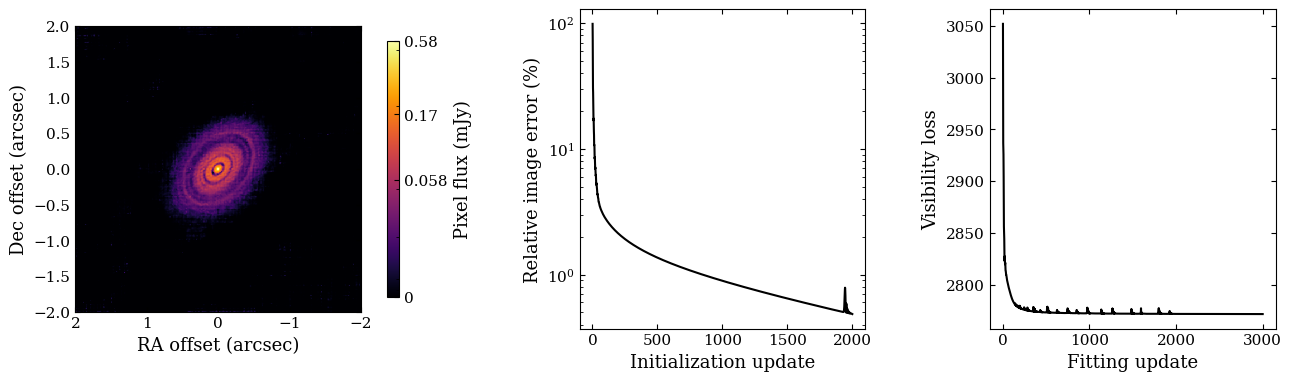

13,378,263 fitted measurements across all four frequency groups
Final initialized-image error: 0.485%
Final 100-update image change: 0.419%


In [12]:
reference = np.load(BASE / 'reference/band6_512.npz')
record = json.loads((BASE / 'reference/run.json').read_text())
full = record['configuration']

fig = show_fit(reference['image'], reference['initial'], reference['init_history'],
                reference['history'], full['fov_arcsec'])
plt.show()
print(f"{record['metrics']['rows']:,} fitted measurements across all four frequency groups")
print(f"Final initialized-image error: {100*record['metrics']['initialization_relative_error']:.3f}%")
print(f"Final 100-update image change: {100*record['metrics']['image_changes'][-1]['relative_image_change']:.3f}%")
